# MenuScan TN · 02.02 Sensibilité des ventes au prix (T7.3, EF-11)

Autrice : Sarra Abdeljaouad

**Question.** Quand un établissement augmente le prix d'un plat, de combien ses ventes baissent-elles ? La réponse est donnée par catégorie, avec un intervalle.

**Mesure.** L'élasticité-prix. Une élasticité de -0,5 veut dire qu'une hausse de prix de 10 % fait baisser les ventes d'environ 5 %.

**Données.** Toutes les versions de prix des articles (`dim_article`, historisé) et les ventes mensuelles par article, de 2024 à 2026.

In [3]:
import sys
sys.path.insert(0, "../00_commun")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from menuscan_analytics import config, data_mining as dm, features
from menuscan_analytics.config import BLEU, GRIS, ORANGE

config.style()

## 1. Les changements de prix

In [4]:
versions = features.versions_prix()
chg = versions[versions.motif_changement != "creation"].copy()
chg["variation"] = chg.prix_ttc / chg.prix_precedent - 1
resume = chg.groupby("motif_changement").agg(changements=("article_id", "size"),
                                            variation_moyenne=("variation", "mean"),
                                            baisses=("variation", lambda v: (v < 0).sum()))
resume

,changements,variation_moyenne,baisses
motif_changement,,,
hausse_cout_cafe,171,0.165,0
repositionnement,540,0.017,279
revision_annuelle,2679,0.079,0


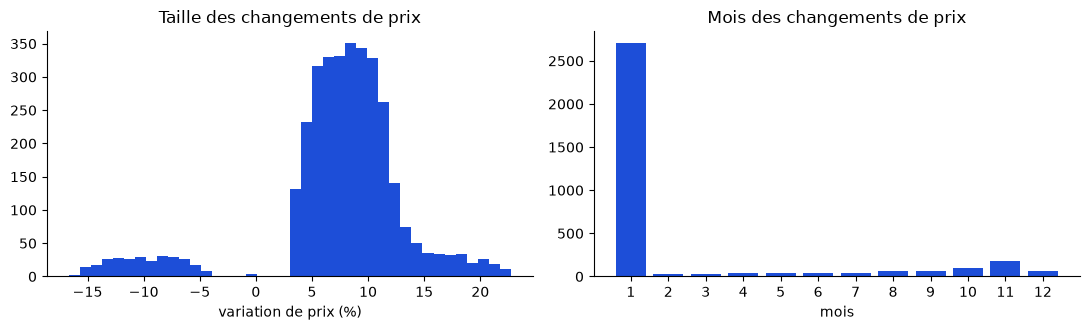

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(chg.variation * 100, bins=40, color=BLEU); axes[0].set_xlabel("variation de prix (%)")
axes[0].set_title("Taille des changements de prix")
m = chg.valide_du.dt.month.value_counts().sort_index()
axes[1].bar(m.index, m.values, color=BLEU); axes[1].set_xticks(range(1, 13))
axes[1].set_title("Mois des changements de prix"); axes[1].set_xlabel("mois")
plt.tight_layout(); config.enregistrer_figure(fig, "DM02_changements_prix"); plt.show()

**Lecture.**
- Les changements sont surtout des hausses de quelques pourcents, en majorité en janvier (révision annuelle).
- À une date donnée, seule une petite partie de la carte d'un établissement change de prix. Les autres plats de la même catégorie servent donc de **groupe témoin** : ils subissent la même saison et la même fréquentation, sans changement de prix.

## 2. Méthode

On compare deux situations pour chaque plat :
- **avant et après** son changement de prix ;
- **par rapport aux autres plats** de la même catégorie, dans le même établissement, le même mois.

Techniquement, c'est une régression de Poisson avec deux effets fixes.
- **Effet « cellule »** (établissement × catégorie × mois) : il absorbe la fréquentation, la saison et le Ramadan.
- **Effet « article »** : il absorbe la popularité propre de chaque plat.

Seule la variation de prix **dans le temps d'un même plat** reste pour mesurer l'effet du prix. Les plats dont le prix n'a jamais changé n'apportent rien à la mesure.

**Pourquoi pas une comparaison entre établissements ?** Un plat plus cher dans un établissement n'y est pas forcément moins vendu à cause du prix. L'établissement peut être plus chic, mieux situé, ou avoir une autre clientèle. L'effet fixe article écarte ce biais.

L'intervalle à 95 % vient d'un bootstrap par établissement (200 tirages).

In [6]:
panel = features.panel_prix(versions)
print(f"{len(panel):,} lignes article x mois ; {panel.article_id.nunique():,} articles ; "
      f"{panel.q.sum():,.0f} unités vendues".replace(",", " "))
e, bas, haut, nb = dm.elasticite_bootstrap(panel, n=200)
print(f"Élasticité, toutes catégories : {e:.2f} [{bas:.2f} ; {haut:.2f}], {nb} articles dont le prix a changé")

62 754 lignes article x mois ; 5 618 articles ; 308 568 unités vendues
Élasticité, toutes catégories : -0.70 [-0.89 ; -0.48], 1307 articles dont le prix a changé


## 3. Contrôle : test placebo

Si la méthode mesure bien l'effet du prix, elle ne doit rien trouver là où le prix n'a pas bougé.

Pour le vérifier :
- on ne garde que les mois **avant** le premier changement de prix de chaque plat, où son prix est constant ;
- on fait comme si le changement avait eu lieu 6 mois plus tôt.

L'élasticité mesurée sur ce faux changement doit être proche de 0.

In [7]:
placebo = panel.sort_values(["article_id", "mois"]).copy()
avant = placebo.groupby("article_id").prix_ttc.transform(lambda s: s.ne(s.iloc[0]).cumsum().eq(0))
placebo["prix_ttc"] = placebo.groupby("article_id").prix_ttc.shift(-6)
placebo = placebo[avant].dropna(subset=["prix_ttc"])
ep, bp, hp, nbp = dm.elasticite_bootstrap(placebo, n=200)
print(f"Placebo (prix décalé de 6 mois) : {ep:.2f} [{bp:.2f} ; {hp:.2f}]")
print("Le placebo ne trouve pas d'effet net : l'intervalle contient 0." if bp <= 0 <= hp else
      "Attention : le placebo trouve un effet. La mesure capte autre chose que le prix.")

Placebo (prix décalé de 6 mois) : -0.00 [-0.37 ; 0.54]
Le placebo ne trouve pas d'effet net : l'intervalle contient 0.


## 4. Élasticité par catégorie

Règles de lecture, fixées avant le calcul :
- **non concluant** si moins de 30 plats ont changé de prix, ou si l'intervalle est plus large que 2 points ;
- sinon, **faible** si l'élasticité est entre -0,5 et 0, **modérée** entre -1 et -0,5, **forte** au-delà de -1 ;
- le résultat est **net** si l'intervalle exclut 0.

La dernière colonne simule l'effet d'une hausse de 5 % sur le chiffre d'affaires de la catégorie, à fréquentation égale. Le calcul : CA × 1,05^(1 + élasticité).

In [8]:
lignes = []
for cat, p in panel.groupby("nom_categorie"):
    e_c, b_c, h_c, n_c = dm.elasticite_bootstrap(p, n=200)
    lignes.append({"categorie": cat, "elasticite": e_c, "bas_95": b_c, "haut_95": h_c, "plats_informatifs": n_c})
el = pd.DataFrame(lignes)

def lecture(r):
    if r.plats_informatifs < 30 or (r.haut_95 - r.bas_95) > 2:
        return "non concluant"
    force = "faible" if r.elasticite > -0.5 else ("modérée" if r.elasticite > -1 else "forte")
    return force + (", net" if r.haut_95 < 0 else ", incertain")

el["lecture"] = el.apply(lecture, axis=1)
el["effet_hausse_5pc_sur_CA"] = np.where(el.lecture == "non concluant", np.nan, 1.05 ** (1 + el.elasticite) - 1)
el = el.sort_values("elasticite").reset_index(drop=True)
config.enregistrer_table(el, "DM02_elasticites_categories", index=False)
globale = pd.DataFrame([{"categorie": "Toutes catégories", "elasticite": e, "bas_95": bas, "haut_95": haut,
                         "plats_informatifs": nb}])
globale["lecture"] = globale.apply(lecture, axis=1)
globale["effet_hausse_5pc_sur_CA"] = 1.05 ** (1 + e) - 1
_ = config.enregistrer_table(globale, "DM02_elasticite_globale", index=False)
el

,categorie,elasticite,bas_95,haut_95,plats_informatifs,lecture,effet_hausse_5pc_sur_CA
0,Glaces,-6.889,-9.565,-4.679,20,non concluant,NaN
1,Tacos,-2.914,-12.157,-0.805,16,non concluant,NaN
2,Crêpes et gaufres,-1.993,-2.724,-1.254,84,"forte, net",-0.047
3,Grillades,-1.944,-3.441,-0.383,42,non concluant,NaN
4,Desserts,-1.613,-2.326,-0.077,69,non concluant,NaN
5,Chicha,-1.515,-4.373,0.157,23,non concluant,NaN
6,Plats,-1.377,-3.103,0.462,56,non concluant,NaN
7,Pâtes,-1.352,-2.493,0.534,42,non concluant,NaN
8,Pâtisseries,-1.157,-2.617,0.499,35,non concluant,NaN
9,Entrées,-1.146,-1.805,0.188,54,"forte, incertain",-0.007


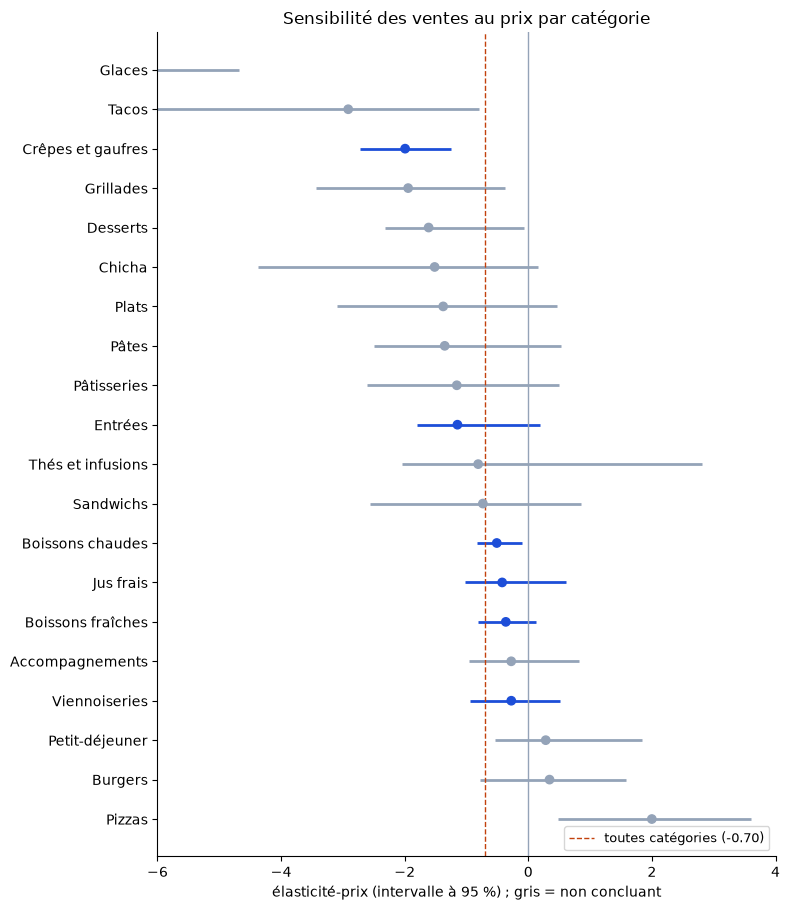

In [9]:
t = el.sort_values("elasticite", ascending=False)
fig, ax = plt.subplots(figsize=(8, 0.4 * len(t) + 1.2))
y = np.arange(len(t))
couleur = [GRIS if l == "non concluant" else BLEU for l in t.lecture]
ax.errorbar(t.elasticite, y, xerr=[t.elasticite - t.bas_95, t.haut_95 - t.elasticite], fmt="none",
            ecolor=couleur, elinewidth=2, capsize=0)
ax.scatter(t.elasticite, y, color=couleur, zorder=3)
ax.axvline(0, color=GRIS, lw=1); ax.axvline(e, color=ORANGE, lw=1, ls="--", label=f"toutes catégories ({e:.2f})")
ax.set_yticks(y, t.categorie); ax.set_xlim(-6, 4)
ax.set_xlabel("élasticité-prix (intervalle à 95 %) ; gris = non concluant")
ax.set_title("Sensibilité des ventes au prix par catégorie"); ax.legend(fontsize=9, loc="lower right")
plt.tight_layout(); config.enregistrer_figure(fig, "DM02_elasticites_categories"); plt.show()

## 5. Conclusion

- **Mesure globale.** Elle est donnée en section 2, avec son intervalle. Le test placebo vérifie que la méthode ne trouve pas d'effet là où il n'y en a pas.
- **Par catégorie.** Seules les catégories avec assez de changements de prix donnent une mesure exploitable. Pour les autres, la réponse honnête est « non concluant » : il faudrait plus d'historique ou des tests de prix volontaires.
- **Usage.** Une catégorie peu sensible supporte une hausse de prix avec un gain de chiffre d'affaires. Une catégorie sensible perd des ventes et peut perdre du chiffre d'affaires. Le tableau de la section 4 donne l'ordre de grandeur pour une hausse de 5 %.

**Limites.**
- La mesure porte sur des hausses modestes (quelques pourcents). Elle ne dit rien d'une hausse de 30 %.
- On mesure le report entre plats d'une même catégorie et d'un même établissement. Un client qui renonce à toute la catégorie, ou à venir, n'est vu que partiellement.
- Les données sont synthétiques : la mesure retrouve la règle du générateur, pas le comportement de vrais clients.